In [1]:
#image gen
!pip install -q diffusers transformers accelerate safetensors

In [2]:
import torch
import matplotlib.pyplot as plt
from IPython.display import display

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Using CPU. Image generation may be slow.")

PyTorch version: 2.11.0+cpu
GPU available: False
Using CPU. Image generation may be slow.


In [3]:
from diffusers import StableDiffusionPipeline

model_id = "CompVis/stable-diffusion-v1-4"

if torch.cuda.is_available():
    pipe = StableDiffusionPipeline.from_pretrained(
        model_id,
        torch_dtype=torch.float16,
        use_safetensors=True
    )
    pipe = pipe.to("cuda")
else:
    pipe = StableDiffusionPipeline.from_pretrained(
        model_id,
        torch_dtype=torch.float32,
        use_safetensors=True
    )
    pipe = pipe.to("cpu")

print("Stable Diffusion model loaded successfully!")

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 16 files:   0%|          | 0/16 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Stable Diffusion model loaded successfully!


  0%|          | 0/25 [00:00<?, ?it/s]

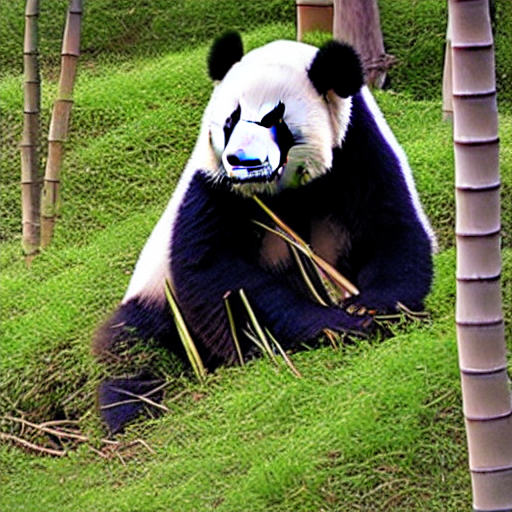

Image saved as generated_image1.png


In [4]:
prompt = "Panda in bamboo field"

image = pipe(
    prompt,
    num_inference_steps=25,
    guidance_scale=7.5
).images[0]

display(image)

image.save("generated_image1.png")

print("Image saved as generated_image1.png")